# 02_eda_v2.ipynb
## v1 대비 변경 사항
- 기존 EDA 섹션 1~6 유지
- 섹션 3-5, 5, 6에 신규 피처 6개 분석 추가

## 목차
1. 데이터 개요 및 기초 체력 점검
2. 타겟 라벨 분포 확인
3. 수치형 파생변수와 이탈의 관계 분석
   - 3-1. RFM 피처
   - 3-2. 활동성 윈도우 피처
   - 3-3. 구매 간격 및 리듬 분석
   - 3-4. 구매 다양성 지표
   - 3-5. [NEW] 구매 트렌드 / 다양성 변화 / 구매 리듬
4. 범주형 파생변수와 이탈의 관계 분석
5. 변수 간 상관관계 분석
   - 5-1. 피처 간 상관계수
   - 5-2. 다중공선성 위험 변수 탐색
   - 5-3. churn과 각 피처 상관관계 순위
6. EDA 종합 결론 및 전처리 전략 확정


## 1. 데이터 개요 및 기초 체력 점검

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.rc('font', family='Malgun Gothic')  # Mac: 'AppleGothic'
plt.rcParams['axes.unicode_minus'] = False
sns.set_theme(style='whitegrid')
pd.options.display.float_format = '{:.4f}'.format

df_analysis = pd.read_csv('../data/hnm_churn_dataset_v2.csv')

print(f'데이터 shape: {df_analysis.shape}')
print(f'결측치 합계: {df_analysis.isnull().sum().sum()}')


데이터 shape: (1143652, 26)
결측치 합계: 3476901


In [3]:
# 1-1. 데이터 구조 및 타입 확인
df_analysis.info()


<class 'pandas.DataFrame'>
RangeIndex: 1143652 entries, 0 to 1143651
Data columns (total 26 columns):
 #   Column                    Non-Null Count    Dtype  
---  ------                    --------------    -----  
 0   customer_id               1143652 non-null  str    
 1   churn                     1143652 non-null  int64  
 2   frequency                 1143652 non-null  int64  
 3   price_mean                1143652 non-null  float64
 4   price_sum                 1143652 non-null  float64
 5   price_max                 1143652 non-null  float64
 6   recency                   1143652 non-null  int64  
 7   frequency_last_90d        1143652 non-null  int64  
 8   frequency_last_180d       1143652 non-null  int64  
 9   avg_purchase_interval     1031690 non-null  float64
 10  std_purchase_interval     924772 non-null   float64
 11  unique_articles           1143652 non-null  int64  
 12  unique_product_groups     1143652 non-null  int64  
 13  index_group_name          1143652 non-

In [4]:
# 1-2. 수치형 요약 통계량
df_analysis.describe()


,churn,frequency,price_mean,price_sum,price_max,recency,frequency_last_90d,frequency_last_180d,avg_purchase_interval,std_purchase_interval,...,unique_product_groups,freq_decay_rate,recent_price_ratio,unique_articles_last_90d,diversity_decay_rate,last_interval,interval_acceleration,FN,Active,age
count,1143652.0000,1143652.0000,1143652.0000,1143652.0000,1143652.0000,1143652.0000,1143652.0000,1143652.0000,1031690.0000,924772.0000,...,1143652.0000,678535.0000,459155.0000,1143652.0000,1143652.0000,1031690.0000,770459.0000,411331.0000,400216.0000,1129563.0000
mean,0.5002,20.0196,0.0292,0.5635,0.0563,180.4354,2.6698,5.8084,18.0815,35.0512,...,3.4423,0.4514,1.0242,2.3278,0.1334,16.8909,0.9489,1.0000,1.0000,36.8462
std,0.5000,31.6590,0.0151,0.9839,0.0364,157.7240,5.9081,10.8550,31.3685,38.6285,...,2.1395,0.3994,0.3864,4.9019,0.2487,51.7545,2.4320,0.0000,0.0000,14.1474
min,0.0000,1.0000,0.0008,0.0008,0.0008,0.0000,0.0000,0.0000,0.0000,0.0000,...,1.0000,0.0000,0.0037,0.0000,0.0000,0.0000,0.0000,1.0000,1.0000,16.0000
25%,0.0000,3.0000,0.0209,0.0869,0.0339,45.0000,0.0000,0.0000,0.0000,8.5000,...,2.0000,0.0000,0.8177,0.0000,0.0000,0.0000,0.0000,1.0000,1.0000,25.0000
50%,1.0000,9.0000,0.0264,0.2338,0.0508,127.0000,0.0000,2.0000,9.6222,25.8094,...,3.0000,0.4167,1.0000,0.0000,0.0000,0.0000,0.0000,1.0000,1.0000,32.0000
75%,1.0000,24.0000,0.0339,0.6234,0.0678,292.0000,3.0000,7.0000,21.6250,47.3507,...,5.0000,0.9000,1.1586,3.0000,0.1667,0.0000,0.8176,1.0000,1.0000,49.0000
max,1.0000,1333.0000,0.5068,41.5563,0.5915,530.0000,320.0000,493.0000,530.0000,371.9382,...,12.0000,1.0000,10.2690,189.0000,1.0000,530.0000,175.0000,1.0000,1.0000,99.0000


In [5]:
# 1-3. 결측치 현황
null_df = pd.DataFrame({
    '결측치 수'  : df_analysis.isnull().sum(),
    '결측치 비율(%)': (df_analysis.isnull().mean() * 100).round(1)
}).query('`결측치 수` > 0').sort_values('결측치 비율(%)', ascending=False)

print(null_df.to_string())


                         결측치 수  결측치 비율(%)
Active                  743436    65.0000
FN                      732321    64.0000
recent_price_ratio      684497    59.9000
freq_decay_rate         465117    40.7000
interval_acceleration   373193    32.6000
std_purchase_interval   218880    19.1000
avg_purchase_interval   111962     9.8000
last_interval           111962     9.8000
fashion_news_frequency   15745     1.4000
age                      14089     1.2000
club_member_status        5699     0.5000


### 결측치 처리 전략

| 컬럼 | 결측 비율 | 처리 방법 | 이유 |
| :--- | :--- | :--- | :--- |
| `recent_price_ratio` | 59.9% | NaN 유지 | 최근 90일 구매 없는 고객 → 자체가 이탈 신호, 트리 모델 위임 |
| `freq_decay_rate` | 40.7% | NaN 유지 | 최근 180일 구매 없는 고객 → 동일 |
| `interval_acceleration` | 32.6% | NaN 유지 | 구매 1회 고객은 간격 계산 불가 |
| `avg_purchase_interval` | 9.8% | NaN 유지 | 구매 1회 고객 |
| `last_interval` | 9.8% | NaN 유지 | 구매 1회 고객 |
| `std_purchase_interval` | 9.8% | NaN 유지 | 구매 1회 고객 |
| `age` | 일부 | 중앙값 대치 | 단순 누락 |
| `FN`, `Active` | 일부 | 0 대치 | 마케팅 미동의 의미 |
| `club_member_status` 등 | 일부 | UNKNOWN 대치 | 범주형 |


## 2. 타겟 라벨 분포 확인

--- 이탈 라벨 분포 ---
        count  ratio(%)
churn                  
1      572053   50.0200
0      571599   49.9800


C:\Users\09048\AppData\Local\Temp\ipykernel_2824\3932282524.py:12: UserWarning: Glyph 44256 (\N{HANGUL SYLLABLE GO}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\09048\AppData\Local\Temp\ipykernel_2824\3932282524.py:12: UserWarning: Glyph 44061 (\N{HANGUL SYLLABLE GAEG}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\09048\AppData\Local\Temp\ipykernel_2824\3932282524.py:12: UserWarning: Glyph 49688 (\N{HANGUL SYLLABLE SU}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\09048\AppData\Local\Temp\ipykernel_2824\3932282524.py:12: UserWarning: Glyph 51060 (\N{HANGUL SYLLABLE I}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\09048\AppData\Local\Temp\ipykernel_2824\3932282524.py:12: UserWarning: Glyph 53448 (\N{HANGUL SYLLABLE TAL}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\09048\AppData\Local\Temp\ipykernel_2824\3932282524.py:12: UserWarning: Glyph 50976 (\N{HANGUL SYLLABLE YU}) missing from font(s) Arial.
  plt.tight_layout()
C:

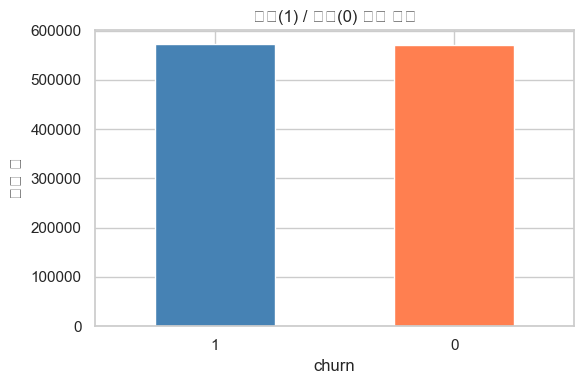

In [6]:
churn_counts = df_analysis['churn'].value_counts()
churn_ratio  = df_analysis['churn'].value_counts(normalize=True) * 100

print('--- 이탈 라벨 분포 ---')
print(pd.DataFrame({'count': churn_counts, 'ratio(%)': churn_ratio.round(2)}))

fig, ax = plt.subplots(figsize=(6, 4))
churn_counts.plot(kind='bar', color=['steelblue','coral'], ax=ax, rot=0)
ax.set_title('이탈(1) / 유지(0) 고객 분포')
ax.set_xlabel('churn')
ax.set_ylabel('고객 수')
plt.tight_layout()
plt.show()


## 3. 수치형 파생변수와 이탈의 관계 분석

In [7]:
def target_summary_with_num(dataframe, target, numerical_col):
    """이탈 여부별 수치형 피처의 평균값을 비교합니다."""
    result = dataframe.groupby(target)[numerical_col].mean().round(4)
    diff   = result[0] - result[1]
    return pd.DataFrame({
        '유지(0)': result[0],
        '이탈(1)': result[1],
        '차이(0-1)': diff
    }, index=[numerical_col])


### 3-1. RFM 피처 분포 비교

In [8]:
rfm_features = ['frequency','price_mean','price_sum','price_max','recency']
rfm_summary  = pd.concat([target_summary_with_num(df_analysis,'churn',col) for col in rfm_features])
print(rfm_summary.to_string())


              유지(0)    이탈(1)   차이(0-1)
frequency   31.3797   8.6686   22.7111
price_mean   0.0283   0.0300   -0.0017
price_sum    0.8885   0.2388    0.6497
price_max    0.0659   0.0467    0.0192
recency    104.5092 256.3014 -151.7922


### 3-2. 활동성 윈도우 피처 분석

In [9]:
activity_features = ['frequency_last_90d','frequency_last_180d']
act_summary = pd.concat([target_summary_with_num(df_analysis,'churn',col) for col in activity_features])
print(act_summary.to_string())


                     유지(0)  이탈(1)  차이(0-1)
frequency_last_90d  4.5290 0.8122   3.7168
frequency_last_180d 9.6549 1.9650   7.6899


### 3-3. 구매 간격 및 리듬 분석

In [10]:
interval_features = ['avg_purchase_interval','std_purchase_interval']
int_summary = pd.concat([target_summary_with_num(df_analysis,'churn',col) for col in interval_features])
print(int_summary.to_string())


                        유지(0)   이탈(1)  차이(0-1)
avg_purchase_interval 19.7634 16.1456   3.6178
std_purchase_interval 37.7014 31.5068   6.1946


### 3-4. 구매 다양성 지표 비교

In [11]:
diversity_features = ['unique_articles','unique_product_groups']
div_summary = pd.concat([target_summary_with_num(df_analysis,'churn',col) for col in diversity_features])
print(div_summary.to_string())


                        유지(0)  이탈(1)  차이(0-1)
unique_articles       26.8996 7.5034  19.3962
unique_product_groups  4.4471 2.4382   2.0089


### 3-5. [NEW] 구매 트렌드 / 다양성 변화 / 구매 리듬

v2에서 새로 추가된 6개 피처의 이탈 여부별 평균값을 비교합니다.

**결측치 처리**: 결측치가 많은 피처(`freq_decay_rate` 40.7%, `recent_price_ratio` 59.9%)는
NaN을 제외한 유효값 기준으로 평균을 계산합니다.
결측 자체가 이탈 신호일 수 있으므로 결측률도 함께 확인합니다.


In [12]:
new_features = [
    'freq_decay_rate', 'recent_price_ratio',
    'unique_articles_last_90d', 'diversity_decay_rate',
    'last_interval', 'interval_acceleration'
]

new_summary = pd.concat([target_summary_with_num(df_analysis,'churn',col) for col in new_features])
print('--- 신규 피처 이탈 여부별 평균값 ---')
print(new_summary.to_string())


--- 신규 피처 이탈 여부별 평균값 ---
                           유지(0)   이탈(1)  차이(0-1)
freq_decay_rate           0.4729  0.4064   0.0665
recent_price_ratio        1.0226  1.0291  -0.0065
unique_articles_last_90d  3.9504  0.7065   3.2439
diversity_decay_rate      0.1673  0.0996   0.0677
last_interval            18.2449 15.3325   2.9124
interval_acceleration     0.9385  0.9684  -0.0299


In [13]:
# 결측률도 이탈 여부별로 확인 (결측 자체가 이탈 신호인지 체크)
print('--- 신규 피처 이탈 여부별 결측률(%) ---')
null_by_churn = df_analysis.groupby('churn')[new_features].apply(
    lambda x: x.isnull().mean() * 100
).round(1).T
null_by_churn.columns = ['유지(0) 결측률','이탈(1) 결측률']
print(null_by_churn.to_string())


--- 신규 피처 이탈 여부별 결측률(%) ---
                          유지(0) 결측률  이탈(1) 결측률
freq_decay_rate             19.7000    61.6000
recent_price_ratio          39.0000    80.7000
unique_articles_last_90d     0.0000     0.0000
diversity_decay_rate         0.0000     0.0000
last_interval                3.4000    16.2000
interval_acceleration       12.0000    53.3000


C:\Users\09048\AppData\Local\Temp\ipykernel_2824\3403832833.py:13: UserWarning: Glyph 50976 (\N{HANGUL SYLLABLE YU}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\09048\AppData\Local\Temp\ipykernel_2824\3403832833.py:13: UserWarning: Glyph 51648 (\N{HANGUL SYLLABLE JI}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\09048\AppData\Local\Temp\ipykernel_2824\3403832833.py:13: UserWarning: Glyph 51060 (\N{HANGUL SYLLABLE I}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\09048\AppData\Local\Temp\ipykernel_2824\3403832833.py:13: UserWarning: Glyph 53448 (\N{HANGUL SYLLABLE TAL}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\09048\AppData\Local\Temp\ipykernel_2824\3403832833.py:13: UserWarning: Glyph 49888 (\N{HANGUL SYLLABLE SIN}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\09048\AppData\Local\Temp\ipykernel_2824\3403832833.py:13: UserWarning: Glyph 44508 (\N{HANGUL SYLLABLE GYU}) missing from font(s) Arial.
  plt.tight_layout()
C:

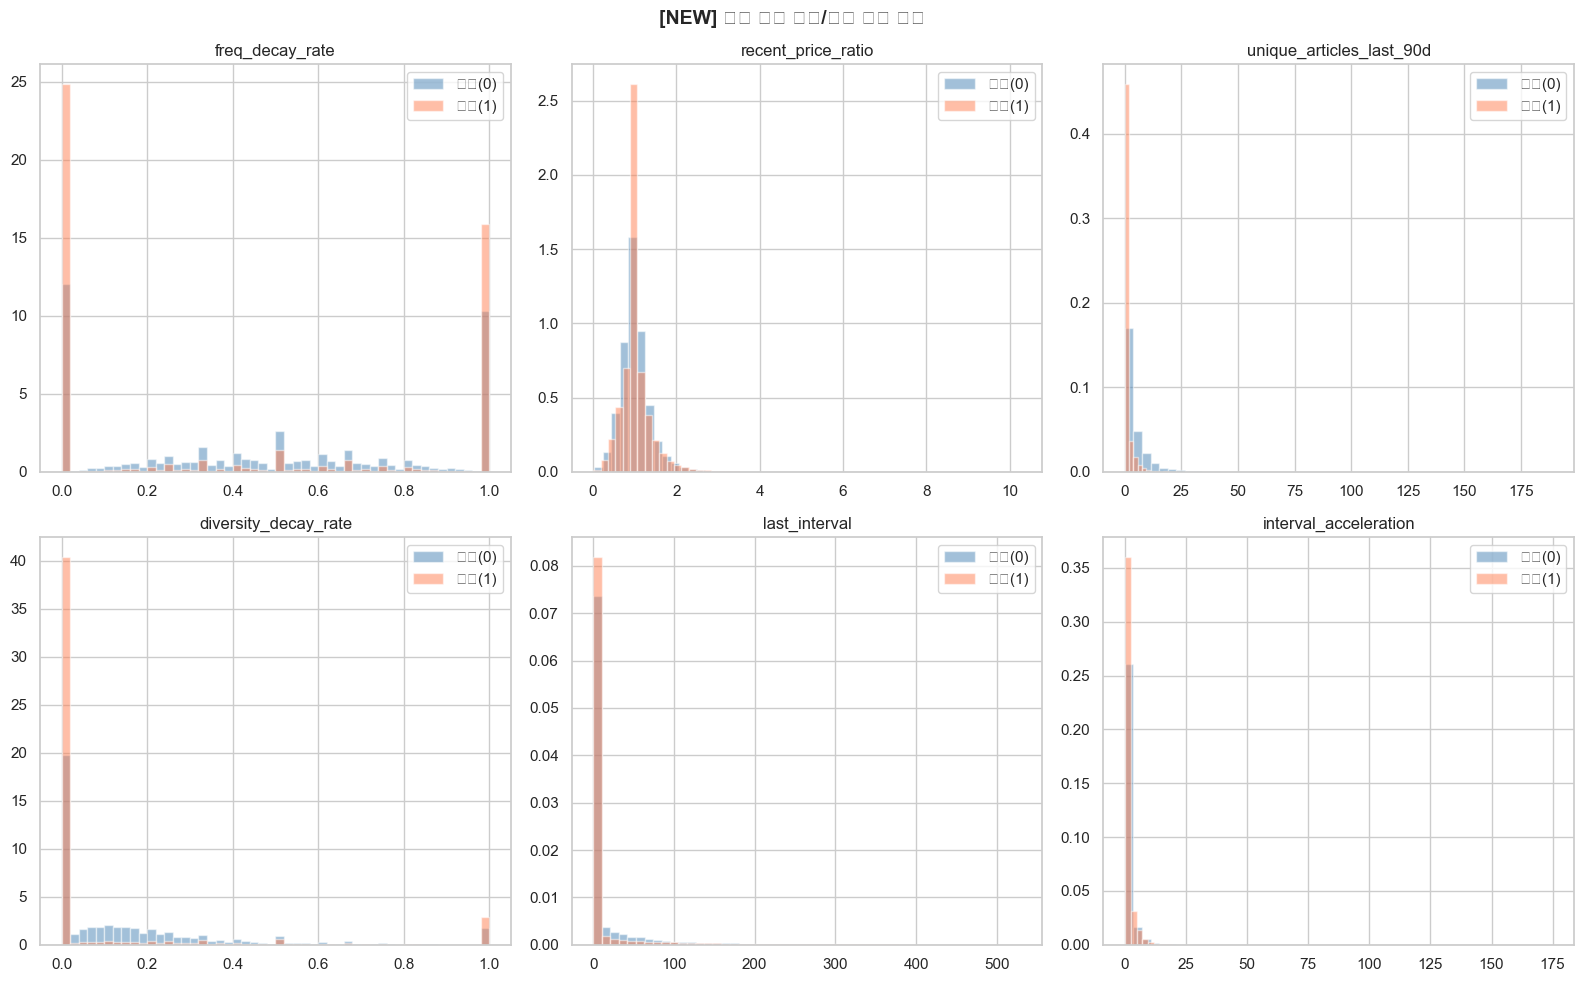

In [14]:
# 신규 피처 시각화 (이탈/유지 분포 비교)
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

for i, col in enumerate(new_features):
    for churn_val, color, label in [(0,'steelblue','유지(0)'), (1,'coral','이탈(1)')]:
        data = df_analysis[df_analysis['churn'] == churn_val][col].dropna()
        axes[i].hist(data, bins=50, alpha=0.5, color=color, label=label, density=True)
    axes[i].set_title(col)
    axes[i].legend()

plt.suptitle('[NEW] 신규 피처 이탈/유지 분포 비교', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


## 4. 범주형 파생변수와 이탈의 관계 분석

C:\Users\09048\AppData\Local\Temp\ipykernel_2824\1585328665.py:8: UserWarning: Glyph 51060 (\N{HANGUL SYLLABLE I}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\09048\AppData\Local\Temp\ipykernel_2824\1585328665.py:8: UserWarning: Glyph 53448 (\N{HANGUL SYLLABLE TAL}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\09048\AppData\Local\Temp\ipykernel_2824\1585328665.py:8: UserWarning: Glyph 47456 (\N{HANGUL SYLLABLE RYUL}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\09048\AppData\Local\Temp\ipykernel_2824\1585328665.py:8: UserWarning: Glyph 48324 (\N{HANGUL SYLLABLE BYEOL}) missing from font(s) Arial.
  plt.tight_layout()
c:\Users\09048\2026project\hnm_churn\venv\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 51060 (\N{HANGUL SYLLABLE I}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
c:\Users\09048\2026project\hnm_churn\venv\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 53448 (\N{HAN

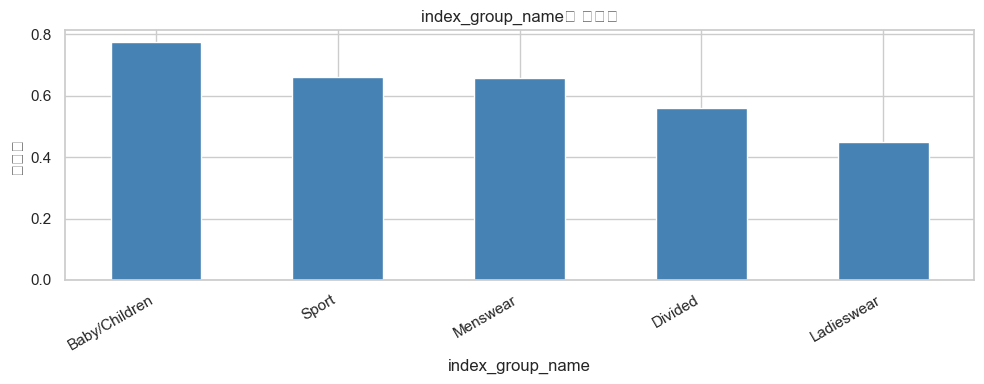

index_group_name
Baby/Children   0.7748
Sport           0.6613
Menswear        0.6589
Divided         0.5599
Ladieswear      0.4498


C:\Users\09048\AppData\Local\Temp\ipykernel_2824\1585328665.py:8: UserWarning: Glyph 51060 (\N{HANGUL SYLLABLE I}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\09048\AppData\Local\Temp\ipykernel_2824\1585328665.py:8: UserWarning: Glyph 53448 (\N{HANGUL SYLLABLE TAL}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\09048\AppData\Local\Temp\ipykernel_2824\1585328665.py:8: UserWarning: Glyph 47456 (\N{HANGUL SYLLABLE RYUL}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\09048\AppData\Local\Temp\ipykernel_2824\1585328665.py:8: UserWarning: Glyph 48324 (\N{HANGUL SYLLABLE BYEOL}) missing from font(s) Arial.
  plt.tight_layout()
c:\Users\09048\2026project\hnm_churn\venv\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 51060 (\N{HANGUL SYLLABLE I}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
c:\Users\09048\2026project\hnm_churn\venv\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 53448 (\N{HAN

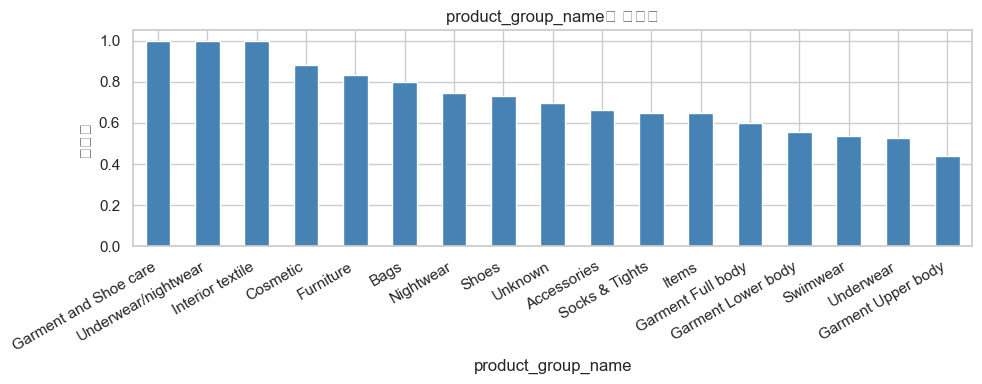

product_group_name
Garment and Shoe care   1.0000
Underwear/nightwear     1.0000
Interior textile        1.0000
Cosmetic                0.8800
Furniture               0.8333
Bags                    0.7978
Nightwear               0.7475
Shoes                   0.7303
Unknown                 0.6983
Accessories             0.6653
Socks & Tights          0.6509
Items                   0.6471
Garment Full body       0.5986
Garment Lower body      0.5569
Swimwear                0.5366
Underwear               0.5286
Garment Upper body      0.4416


C:\Users\09048\AppData\Local\Temp\ipykernel_2824\1585328665.py:8: UserWarning: Glyph 51060 (\N{HANGUL SYLLABLE I}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\09048\AppData\Local\Temp\ipykernel_2824\1585328665.py:8: UserWarning: Glyph 53448 (\N{HANGUL SYLLABLE TAL}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\09048\AppData\Local\Temp\ipykernel_2824\1585328665.py:8: UserWarning: Glyph 47456 (\N{HANGUL SYLLABLE RYUL}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\09048\AppData\Local\Temp\ipykernel_2824\1585328665.py:8: UserWarning: Glyph 48324 (\N{HANGUL SYLLABLE BYEOL}) missing from font(s) Arial.
  plt.tight_layout()
c:\Users\09048\2026project\hnm_churn\venv\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 51060 (\N{HANGUL SYLLABLE I}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
c:\Users\09048\2026project\hnm_churn\venv\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 53448 (\N{HAN

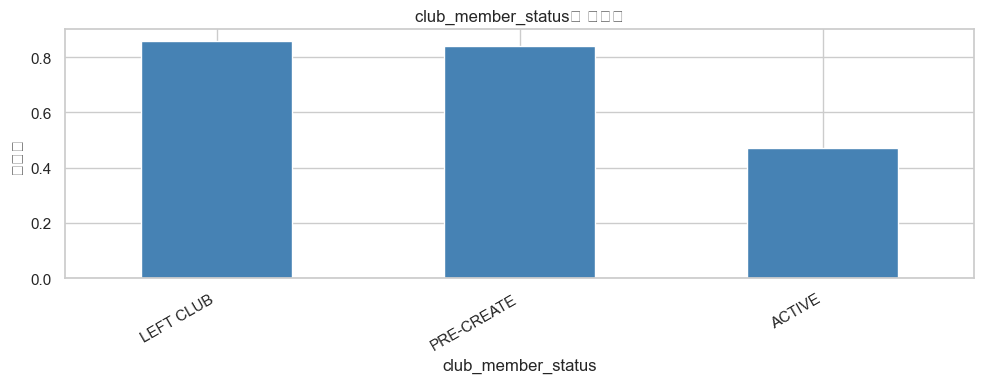

club_member_status
LEFT CLUB    0.8571
PRE-CREATE   0.8413
ACTIVE       0.4727


C:\Users\09048\AppData\Local\Temp\ipykernel_2824\1585328665.py:8: UserWarning: Glyph 51060 (\N{HANGUL SYLLABLE I}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\09048\AppData\Local\Temp\ipykernel_2824\1585328665.py:8: UserWarning: Glyph 53448 (\N{HANGUL SYLLABLE TAL}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\09048\AppData\Local\Temp\ipykernel_2824\1585328665.py:8: UserWarning: Glyph 47456 (\N{HANGUL SYLLABLE RYUL}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\09048\AppData\Local\Temp\ipykernel_2824\1585328665.py:8: UserWarning: Glyph 48324 (\N{HANGUL SYLLABLE BYEOL}) missing from font(s) Arial.
  plt.tight_layout()
c:\Users\09048\2026project\hnm_churn\venv\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 51060 (\N{HANGUL SYLLABLE I}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
c:\Users\09048\2026project\hnm_churn\venv\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 53448 (\N{HAN

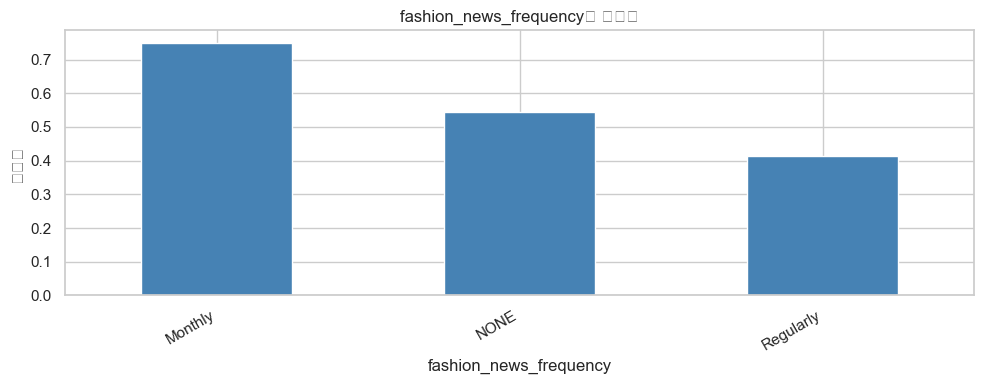

fashion_news_frequency
Monthly     0.7491
NONE        0.5431
Regularly   0.4132


In [15]:
def target_vs_category_visual(dataframe, target, cat_col):
    churn_rate = dataframe.groupby(cat_col)[target].mean().sort_values(ascending=False)
    plt.figure(figsize=(10, 4))
    churn_rate.plot(kind='bar', color='steelblue')
    plt.title(f'{cat_col}별 이탈률')
    plt.ylabel('이탈률')
    plt.xticks(rotation=30, ha='right')
    plt.tight_layout()
    plt.show()
    print(churn_rate.round(4).to_string())

cat_features = ['index_group_name','product_group_name',
                'club_member_status','fashion_news_frequency']

for col in cat_features:
    target_vs_category_visual(df_analysis, 'churn', col)


## 5. 변수 간 상관관계 분석

C:\Users\09048\AppData\Local\Temp\ipykernel_2824\3635684210.py:20: UserWarning: Glyph 54588 (\N{HANGUL SYLLABLE PI}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\09048\AppData\Local\Temp\ipykernel_2824\3635684210.py:20: UserWarning: Glyph 52376 (\N{HANGUL SYLLABLE CEO}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\09048\AppData\Local\Temp\ipykernel_2824\3635684210.py:20: UserWarning: Glyph 44036 (\N{HANGUL SYLLABLE GAN}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\09048\AppData\Local\Temp\ipykernel_2824\3635684210.py:20: UserWarning: Glyph 49345 (\N{HANGUL SYLLABLE SANG}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\09048\AppData\Local\Temp\ipykernel_2824\3635684210.py:20: UserWarning: Glyph 44288 (\N{HANGUL SYLLABLE GWAN}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\09048\AppData\Local\Temp\ipykernel_2824\3635684210.py:20: UserWarning: Glyph 44228 (\N{HANGUL SYLLABLE GYE}) missing from font(s) Arial.
  plt.tight_layout

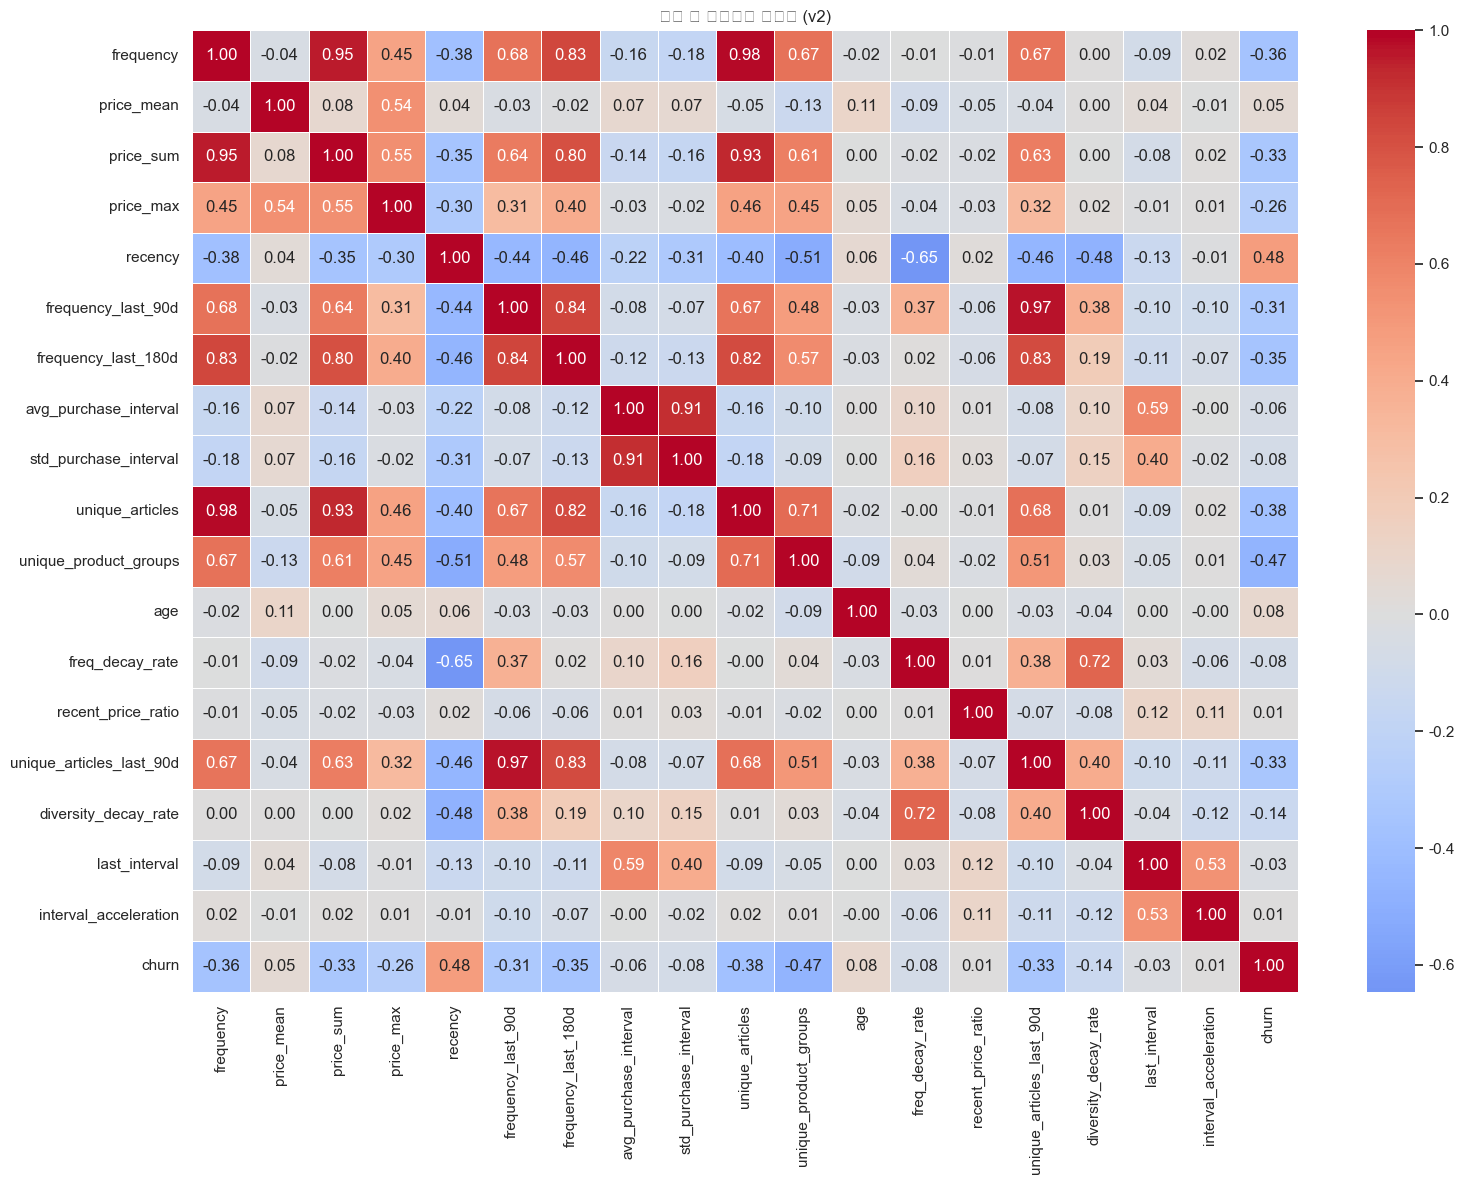

In [16]:
# 수치형 컬럼만 선택
num_features = [
    'frequency','price_mean','price_sum','price_max','recency',
    'frequency_last_90d','frequency_last_180d',
    'avg_purchase_interval','std_purchase_interval',
    'unique_articles','unique_product_groups','age',
    'freq_decay_rate','recent_price_ratio',
    'unique_articles_last_90d','diversity_decay_rate',
    'last_interval','interval_acceleration',
    'churn'
]

correlation_matrix = df_analysis[num_features].astype('float32').corr()

# 5-1. 히트맵
plt.figure(figsize=(16, 12))
sns.heatmap(correlation_matrix, annot=True, fmt='.2f', cmap='coolwarm',
            center=0, linewidths=0.5)
plt.title('피처 간 상관관계 히트맵 (v2)')
plt.tight_layout()
plt.show()


In [17]:
# 5-2. 다중공선성 위험 변수 탐색 (0.7 이상)
high_corr_pairs = []
cols = correlation_matrix.columns.tolist()
for i in range(len(cols)):
    for j in range(i+1, len(cols)):
        if cols[i] == 'churn' or cols[j] == 'churn':
            continue
        val = abs(correlation_matrix.loc[cols[i], cols[j]])
        if val >= 0.7:
            high_corr_pairs.append((cols[i], cols[j], round(val, 4)))

high_corr_pairs.sort(key=lambda x: x[2], reverse=True)
print('--- 피처 간 상관관계 0.7 이상 쌍 ---')
for a, b, v in high_corr_pairs:
    print(f'  {a:<35} ↔ {b:<35} : {v}')


--- 피처 간 상관관계 0.7 이상 쌍 ---
  frequency                           ↔ unique_articles                     : 0.9823
  frequency_last_90d                  ↔ unique_articles_last_90d            : 0.9728
  frequency                           ↔ price_sum                           : 0.9519
  price_sum                           ↔ unique_articles                     : 0.9311
  avg_purchase_interval               ↔ std_purchase_interval               : 0.9114
  frequency_last_90d                  ↔ frequency_last_180d                 : 0.8433
  frequency                           ↔ frequency_last_180d                 : 0.8338
  frequency_last_180d                 ↔ unique_articles_last_90d            : 0.8262
  frequency_last_180d                 ↔ unique_articles                     : 0.822
  price_sum                           ↔ frequency_last_180d                 : 0.8019
  freq_decay_rate                     ↔ diversity_decay_rate                : 0.7248
  unique_articles                     ↔

--- churn과 상관관계 순위 (절대값 기준) ---
recency                    0.4812
unique_product_groups      0.4695
unique_articles            0.3768
frequency                  0.3587
frequency_last_180d        0.3542
unique_articles_last_90d   0.3309
price_sum                  0.3302
frequency_last_90d         0.3146
price_max                  0.2644
diversity_decay_rate       0.1360
age                        0.0814
std_purchase_interval      0.0793
freq_decay_rate            0.0778
avg_purchase_interval      0.0575
price_mean                 0.0545
last_interval              0.0281
recent_price_ratio         0.0072
interval_acceleration      0.0059


C:\Users\09048\AppData\Local\Temp\ipykernel_2824\2576260283.py:13: UserWarning: Glyph 49345 (\N{HANGUL SYLLABLE SANG}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\09048\AppData\Local\Temp\ipykernel_2824\2576260283.py:13: UserWarning: Glyph 44288 (\N{HANGUL SYLLABLE GWAN}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\09048\AppData\Local\Temp\ipykernel_2824\2576260283.py:13: UserWarning: Glyph 44228 (\N{HANGUL SYLLABLE GYE}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\09048\AppData\Local\Temp\ipykernel_2824\2576260283.py:13: UserWarning: Glyph 49688 (\N{HANGUL SYLLABLE SU}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\09048\AppData\Local\Temp\ipykernel_2824\2576260283.py:13: UserWarning: Glyph 51208 (\N{HANGUL SYLLABLE JEOL}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\09048\AppData\Local\Temp\ipykernel_2824\2576260283.py:13: UserWarning: Glyph 45824 (\N{HANGUL SYLLABLE DAE}) missing from font(s) Arial.
  plt.tight_layou

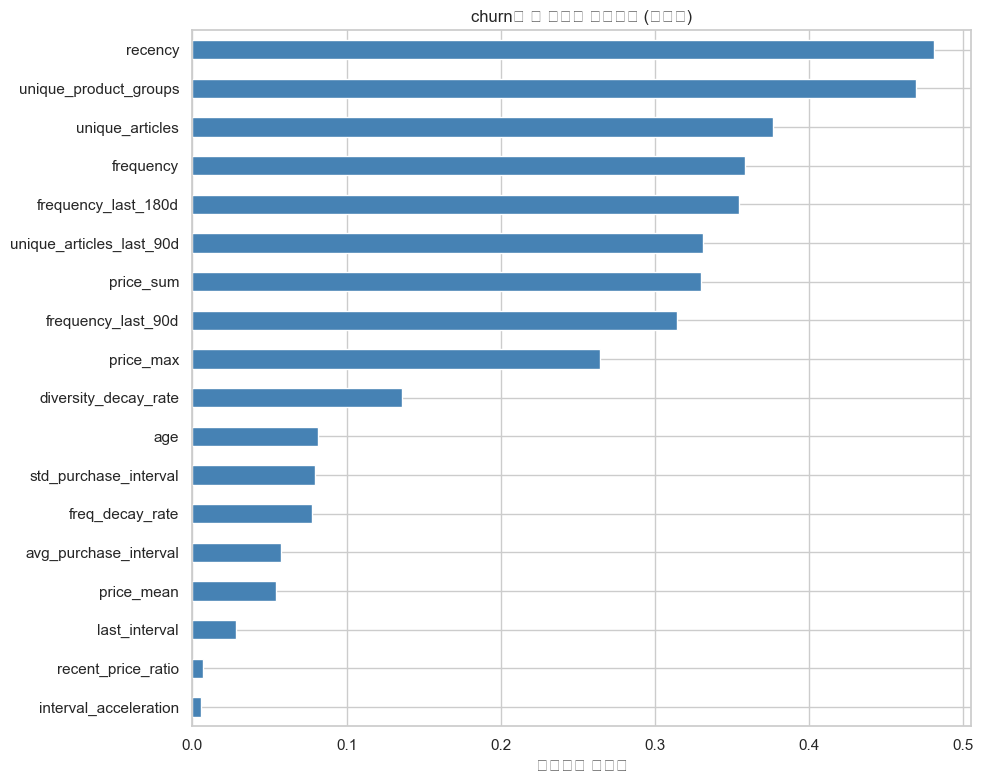

In [18]:
# 5-3. churn과 각 피처 상관관계 순위
churn_corr = correlation_matrix['churn'].drop('churn').abs().sort_values(ascending=False)

print('--- churn과 상관관계 순위 (절대값 기준) ---')
print(churn_corr.round(4).to_string())

# 시각화
plt.figure(figsize=(10, 8))
churn_corr.plot(kind='barh', color='steelblue')
plt.title('churn과 각 피처의 상관관계 (절대값)')
plt.xlabel('상관계수 절대값')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


## 6. EDA 종합 결론 및 전처리 전략 확정

### 6-1. 주요 인사이트 요약

**기존 피처 (v1)**
- `recency`가 이탈과 가장 높은 상관관계 → 오래 안 산 고객일수록 이탈 가능성 높음
- `unique_product_groups`, `unique_articles`, `frequency`가 뒤를 이음
- 유지 고객이 이탈 고객보다 구매 다양성, 빈도 모두 높음

**신규 피처 (v2 추가)**
- `freq_decay_rate`: 유지 고객은 최근 90일/180일 구매 비율이 높고, 이탈 고객은 낮음
  → 구매가 줄어드는 고객이 이탈로 이어지는 패턴 확인
- `recent_price_ratio`: 이탈 고객의 최근 지출이 전체 평균 대비 낮은 경향
- `interval_acceleration`: 이탈 고객의 마지막 구매 간격이 평균보다 길어지는 패턴
- **결측 자체가 이탈 신호**: `freq_decay_rate`, `recent_price_ratio` 결측률이
  이탈 고객에서 더 높다면 NaN 유지 전략이 더욱 유효

### 6-2. 전처리 전략

| 항목 | 전략 |
| :--- | :--- |
| `FN`, `Active` | 0 대치 |
| `age` | 중앙값 대치 |
| `club_member_status`, `fashion_news_frequency` | UNKNOWN 대치 |
| `avg/std_purchase_interval`, `last_interval` | NaN 유지 (트리 모델 위임) |
| `freq_decay_rate`, `recent_price_ratio`, `interval_acceleration` | NaN 유지 (결측 자체가 이탈 신호) |
| `diversity_decay_rate` | NaN 없음, 처리 불필요 |
| 범주형 인코딩 | 원-핫 인코딩 (`drop_first=False`) |
